In [2]:
import os
import matplotlib.pyplot as plt
import numpy as np
import scipy.integrate as sp
import math as mt
from scipy.integrate import solve_ivp

output_dir = "/home/max/Documents/private/Uni/masterthesis/paper/plots"
os.makedirs(output_dir, exist_ok=True)

In [3]:
def Gamma(d): #Define Gamma function as numerical integral
    result, _ = sp.quad(lambda t: t**(d-1)*np.exp(-t), 0, np.inf) #returns only numerical value, _ "deletes" the error value from sp.quad
    return result

In [11]:
#coupled deq derived from wetterich eq
def flow(k, S, d, rho): #del_t Gamma_k = ...
    mq , l = S #mq = m², l = lambda

    prefactorlambda = (12 * k**(d + 1))/((4 * np.pi)**(d/2) * Gamma(d/2 + 1))

    prefactormq = (2 * k**(d + 1))/((4 * np.pi)**(d/2) * Gamma(d/2 + 1))
 
    dldk =  prefactorlambda * ((1/18 * l**2) / ((k**2 + mq + 1/6 * l * rho)**3) + (1/2 * l**2) / ((k**2 + mq + 1/2 * l * rho)**3))
    
    dmqdk = prefactormq * ((-1/6 * l) / ((k**2 + mq + 1/6 * l * rho)**2) - (1/2 * l) / ((k**2 + mq + 1/2 * l * rho)**2) ) - rho/6 * dldk

    return [dmqdk, dldk]

In [58]:
#initial conditions
d = 3.0
rho = 50.0
k0 = 1000.0
mq0 = 16
k_end = 0

l0_list=[0.0001, 0.001, 0.01, 0.1, 1, 10, 20, 100]
mq0_list=[-16, 16]

k_eval = np.linspace(k0, k_end, 1000)


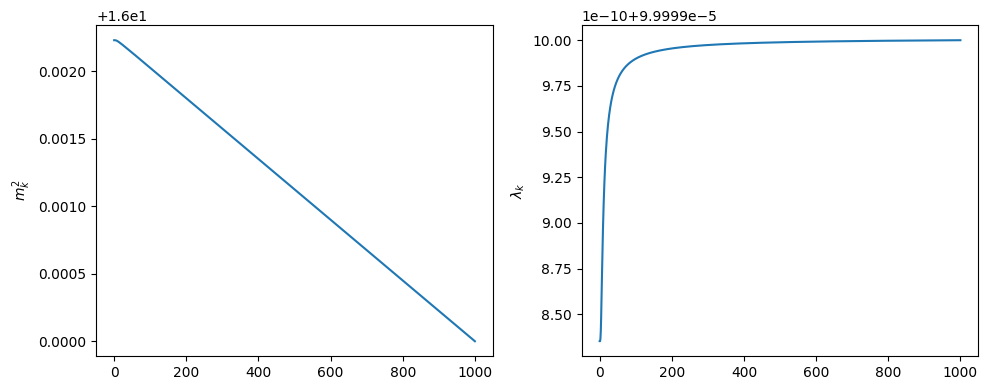

In [54]:
l0test=0.0001
mq0test=16

sol = solve_ivp(flow, t_span=(k0, k_end), y0=[mq0test, l0test], t_eval=k_eval, method='RK45', args=(d, rho), rtol=1e-10, atol=1e-14)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(sol.t, sol.y[0])
ax1.set_ylabel(r"$m^2_k$")

ax2.plot(sol.t, sol.y[1])
ax2.set_ylabel(r"$\lambda_k$")


plt.tight_layout()
plt.show()

In [59]:
k_eval = np.linspace(k0, k_end, 1000)

solutions = {}
for l0 in l0_list:
    sol = solve_ivp(
        flow, (k0, k_end), [mq0, l0],
        t_eval=k_eval, method="LSODA",
        rtol=1e-8, atol=1e-12,
        args=(d, rho),
    )
    if not sol.success:
        print(f"λ_0={l0}: {sol.message}")
    solutions[l0] = sol

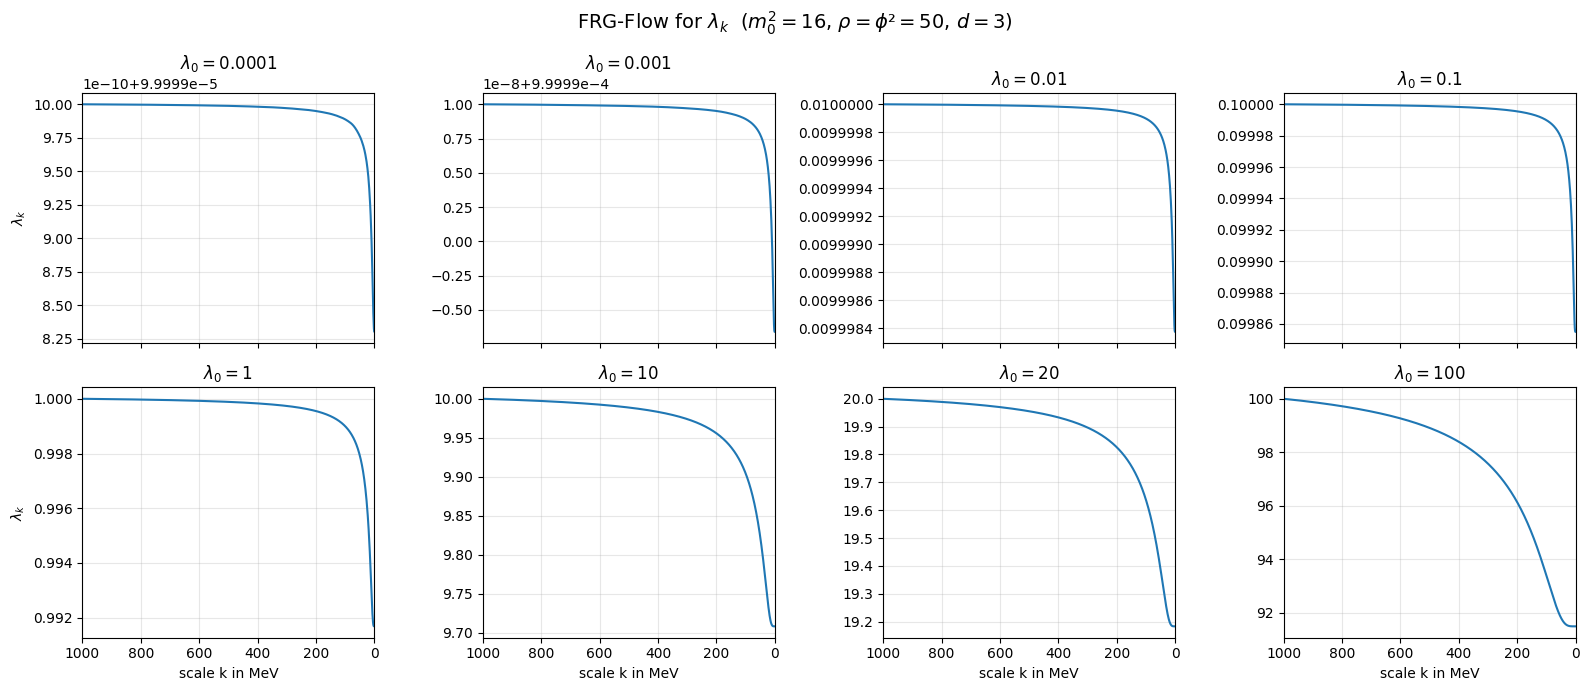

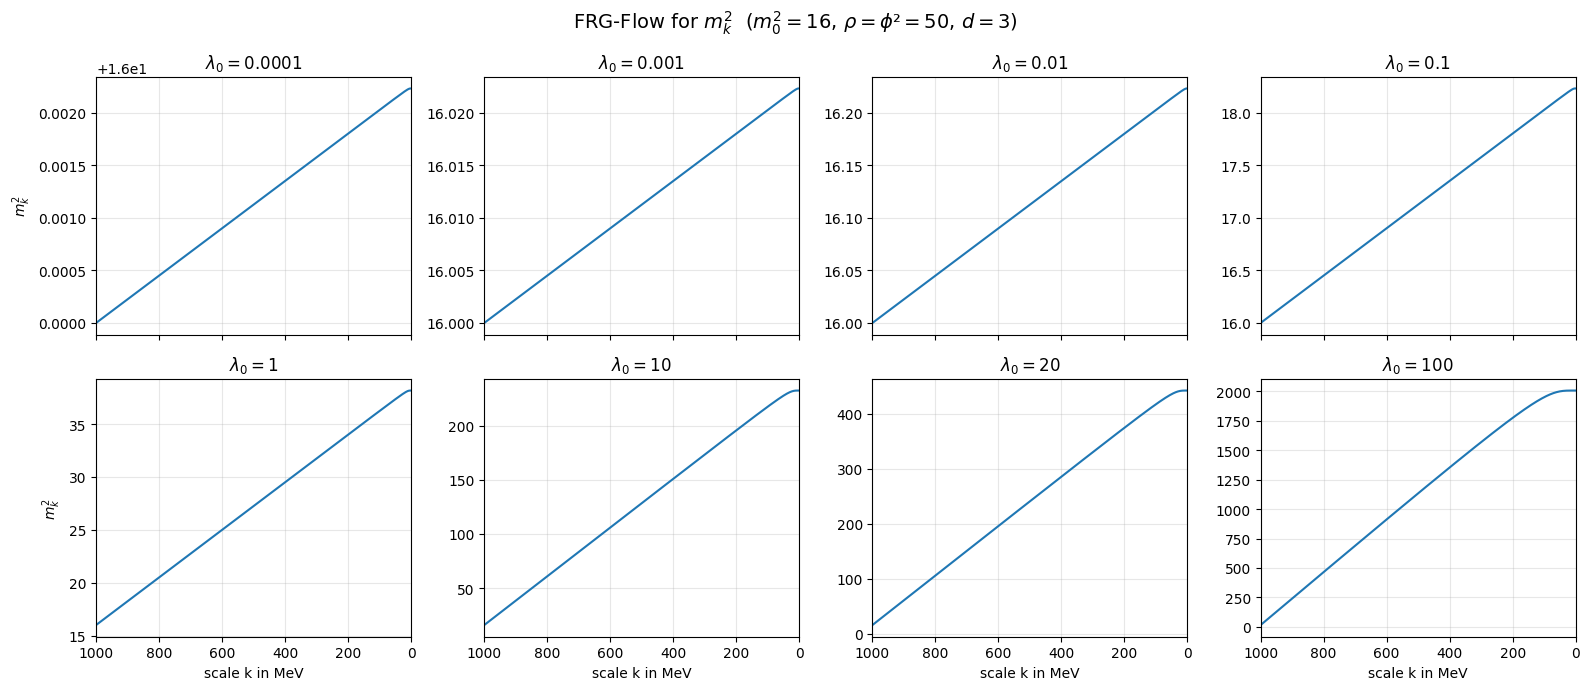

In [66]:
def tile_plot(component, ylabel, title):
    fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
    for ax, l0 in zip(axes.ravel(), l0_list):
        sol = solutions[l0]
        ax.plot(sol.t, sol.y[component], color="C0")
        ax.set_xlim(k0, k_end)            # UV (k groß) links, IR (k=0) rechts
        ax.set_title(fr"$\lambda_0 = {l0}$")
        ax.grid(alpha=0.3)

    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel)
    for ax in axes[-1, :]:
        ax.set_xlabel("scale k in MeV")

    fig.suptitle(title + fr"  ($m^2_0={mq0:g}$, $\rho=\phi²={rho:g}$, $d={d:g}$)", fontsize=14)
    fig.tight_layout()
    return fig

tile_plot(1, r"$\lambda_k$", r"FRG-Flow for $\lambda_k$").savefig(os.path.join(output_dir, "lambda_flow.pdf"), bbox_inches="tight")
tile_plot(0, r"$m^2_k$", r"FRG-Flow for $m^2_k$").savefig(os.path.join(output_dir, "mq_flow.pdf"), bbox_inches="tight")